<a href="https://colab.research.google.com/github/SRXKaiser/analitica-de-datos/blob/main/Practicas%20U3/Karely/1-Arboles_de_desicion_y_LN_DataSet_Libre_BestSellers_23111441_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DATASET DE BESTSELLERS Y SUS CATEGORIAS**

**Alumno:** Karely Pérez Vargas

**Número de control**: 23111441

In [1]:
#acceso a drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#libreria manipulacion de datos
import pandas as pd

#libreria para calculos numericos y estadisticos
import numpy as np

#libreria para graficos
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector

from sklearn.linear_model import LinearRegression
# Importamos root_mean_squared_error en lugar de usar el argumento deprecado 'squared'
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score

In [ ]:
# conversion de archivo csv a dataframe ignorando filas con errores de formato
bk_df = pd.read_csv('/content/drive/MyDrive/Analítica de datos/bestsellers_with_categories.csv', on_bad_lines='skip')
bk_df

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction
...,...,...,...,...,...,...,...
545,Wrecking Ball (Diary of a Wimpy Kid Book 14),Jeff Kinney,4.9,9413,8,2019,Fiction
546,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2016,Non Fiction
547,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2017,Non Fiction
548,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2018,Non Fiction


In [ ]:
bk_df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [ ]:
bk_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    object 
 1   Author       550 non-null    object 
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 30.2+ KB


In [ ]:
bk_df.nunique()

,0
Name,351
Author,248
User Rating,14
Reviews,346
Price,40
Year,11
Genre,2


In [ ]:
bk_df.shape

(550, 7)

In [ ]:
bk_df.isnull().sum()

,0
Name,0
Author,0
User Rating,0
Reviews,0
Price,0
Year,0
Genre,0


In [ ]:
bk_df['User Rating'].nunique()

sorted(bk_df['User Rating'].dropna().unique())

bk_df['User Rating'].value_counts().sort_index()

,count
User Rating,
3.3,1
3.6,1
3.8,2
3.9,3
4.0,14
4.1,6
4.2,8
4.3,25
4.4,38


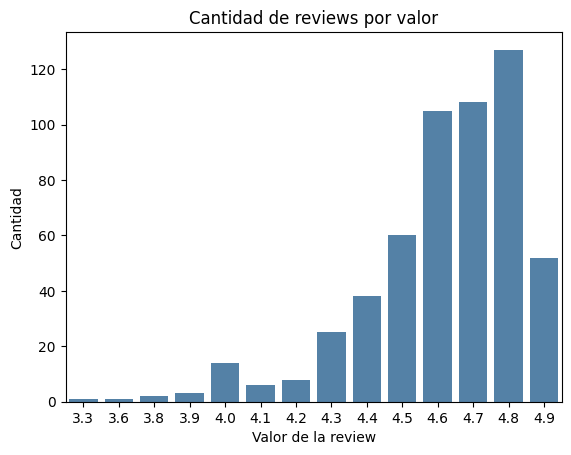

In [ ]:
conteo = bk_df['User Rating'].value_counts().sort_index().reset_index()
conteo.columns = ['valor', 'cantidad']

sns.barplot(data=conteo, x='valor', y='cantidad', color='steelblue')
plt.title('Cantidad de reviews por valor')
plt.xlabel('Valor de la review')
plt.ylabel('Cantidad')
plt.show()

In [ ]:
top10=bk_df['Author'].value_counts().head(10)
top10

,count
Author,
Jeff Kinney,12
Suzanne Collins,11
Gary Chapman,11
Rick Riordan,11
American Psychological Association,10
Dr. Seuss,9
Gallup,9
Rob Elliott,8
Bill O'Reilly,7


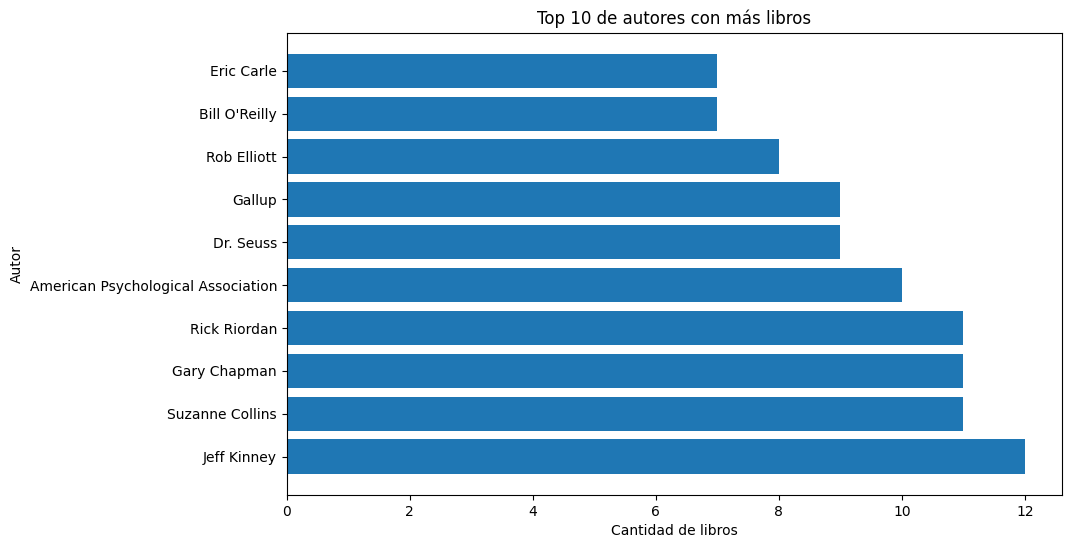

In [ ]:
plt.figure(figsize=(10, 6))
plt.barh(top10.index, top10.values)
plt.xlabel('Cantidad de libros')
plt.ylabel('Autor')
plt.title('Top 10 de autores con más libros')
plt.show()

In [ ]:
libros10=bk_df.nlargest(10, 'Price')
libros10

,Name,Author,User Rating,Reviews,Price,Year,Genre
69,Diagnostic and Statistical Manual of Mental Di...,American Psychiatric Association,4.5,6679,105,2013,Non Fiction
70,Diagnostic and Statistical Manual of Mental Di...,American Psychiatric Association,4.5,6679,105,2014,Non Fiction
473,The Twilight Saga Collection,Stephenie Meyer,4.7,3801,82,2009,Fiction
151,Hamilton: The Revolution,Lin-Manuel Miranda,4.9,5867,54,2016,Non Fiction
346,The Book of Basketball: The NBA According to T...,Bill Simmons,4.7,858,53,2009,Non Fiction
159,Harry Potter Paperback Box Set (Books 1-7),J. K. Rowling,4.8,13471,52,2016,Fiction
271,Publication Manual of the American Psychologic...,American Psychological Association,4.5,8580,46,2009,Non Fiction
272,Publication Manual of the American Psychologic...,American Psychological Association,4.5,8580,46,2010,Non Fiction
273,Publication Manual of the American Psychologic...,American Psychological Association,4.5,8580,46,2011,Non Fiction
274,Publication Manual of the American Psychologic...,American Psychological Association,4.5,8580,46,2012,Non Fiction


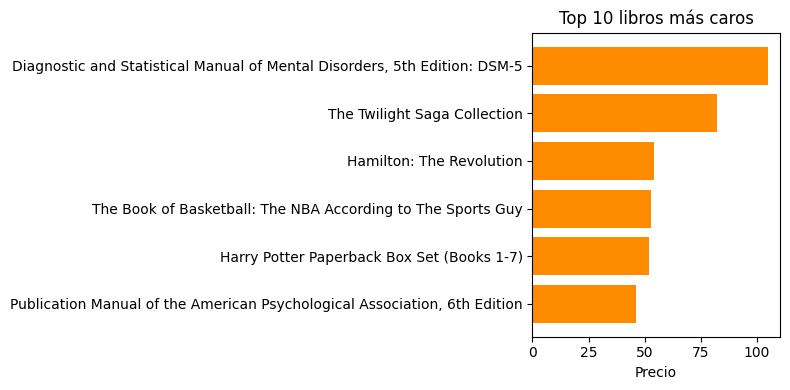

In [ ]:
plt.figure(figsize=(8, 4))
plt.barh(libros10['Name'][::-1], libros10['Price'][::-1], color='darkorange')

plt.title('Top 10 libros más caros')
plt.xlabel('Precio')
plt.ylabel('')
plt.tight_layout()
plt.show()

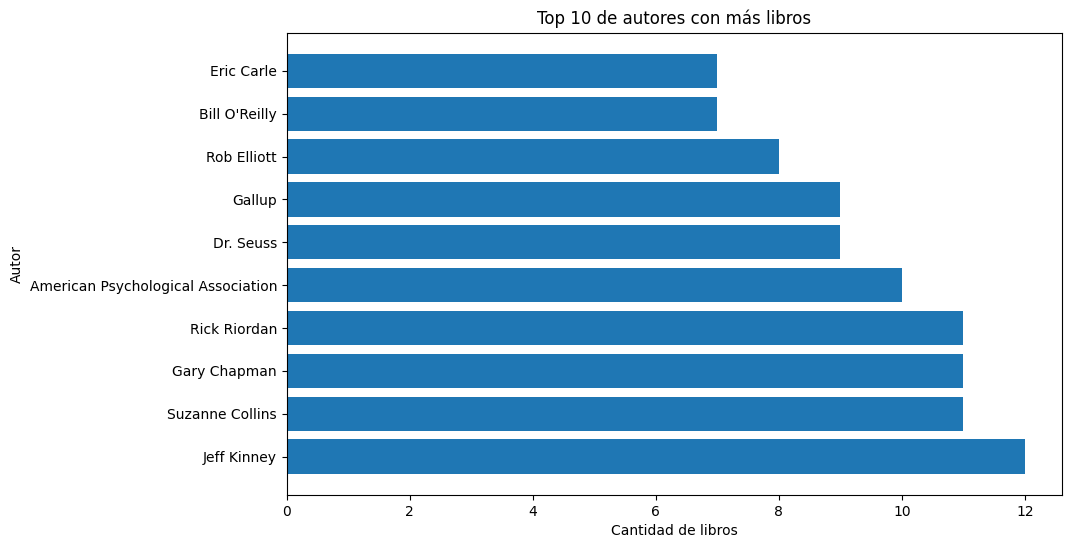

In [ ]:
plt.figure(figsize=(10, 6))
plt.barh(top10.index, top10.values)
plt.xlabel('Cantidad de libros')
plt.ylabel('Autor')
plt.title('Top 10 de autores con más libros')
plt.show()

<Axes: xlabel='Year', ylabel='Price'>

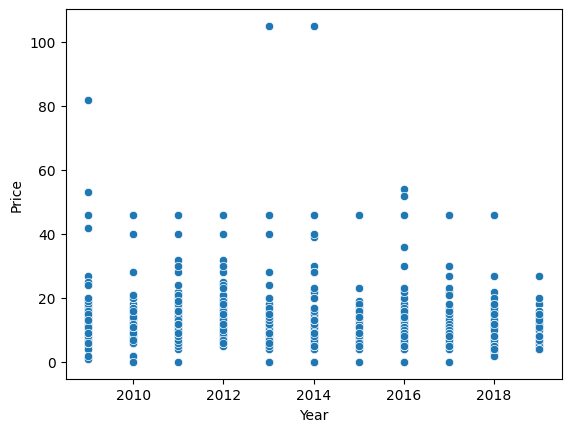

In [ ]:
sns.scatterplot(x='Year', y='Price', data=bk_df)

<Axes: xlabel='Reviews', ylabel='Price'>

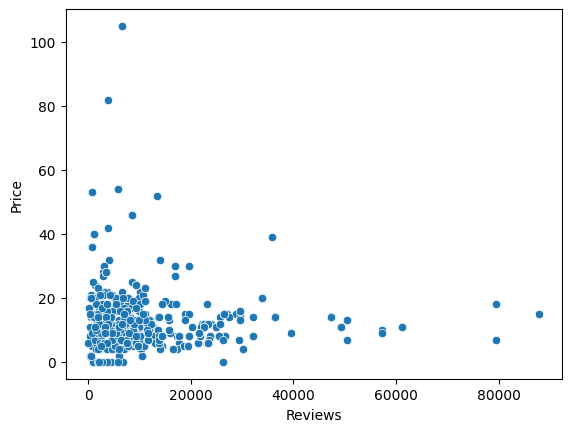

In [ ]:
sns.scatterplot(x='Reviews', y='Price', data=bk_df)

<Axes: xlabel='User Rating', ylabel='Price'>

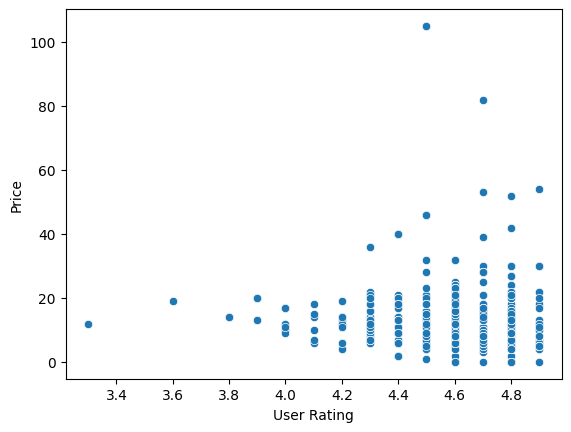

In [ ]:
sns.scatterplot(x='User Rating', y='Price', data=bk_df)

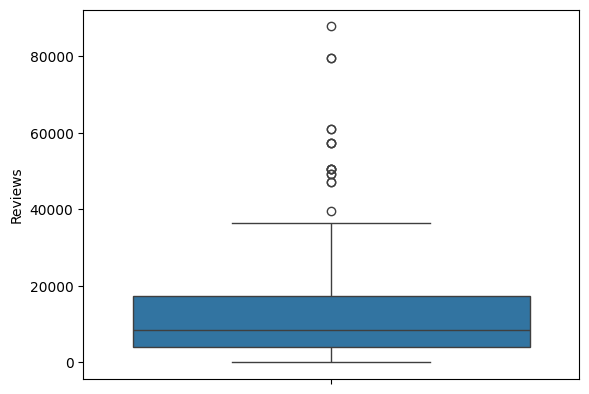

In [ ]:
figsize=(5,8)
ax = sns.boxplot(y='Reviews', data=bk_df)


---------------------------------------------------------------------------------------------

## **INICIO DE MODELO DE ML: REGRESION LINEAL**

In [ ]:
# Se separan las variables del dataframe: en X quedan los predictores y en y la variable de respuesta o salida (Item_Outlet_Sales).
X = bk_df.drop('Reviews', axis = 1) #variables de entrada - Caracteristica
y = bk_df['Reviews'] #variable salida -variable predictora - Objetivo

In [ ]:
# Se divide el conjunto en entrenamiento y prueba
#92% conjunto de entrenamiento(train) (por alguna razón esta canitdad de datos de entrenamiento con un random state=2, me da buenos resultados)
#8% para el conjunto de prueba (test)

from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X,#variable entrada
                                                y,#variable salida o predictora
                                                train_size=.92, # tamaño conjunto entrenamiento
                                                random_state=2) #para mantener mismo conjunto de datos

In [ ]:
#Pipeline
#PARA VARIABLES NUMERICAS
num_pipeline = make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler())
#PARA VARIABLES CATEGORICAS
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))

#UNE PREPROCESAMIENTOS
preprocessing = ColumnTransformer([
    ('num', num_pipeline, make_column_selector(dtype_include=np.number)), #detecta TODAS columnas numericas                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     , make_column_selector(dtype_include=np.number)),
    ('cat', cat_pipeline, make_column_selector(dtype_include=object))])   #detecta TODAS columnas categoricas

In [ ]:
# Se crea el pipeline para la predicción, que incluye el de procesamiento creado anteriormente y la regresión lineal

#CREA PIPELINE
lr_model = make_pipeline(preprocessing, LinearRegression())
    #PREPROCESING, procesa los datos (relleno de nulos, escalado (minMaxScaler), codificacion (OneHOtEnconder))
    #LinearRegresion, aplica modelo de regresion lineal a los datos ya entrenados

#ENTRENA Y AJUSTA TODO EL PIPELINE CON LOS DATOS DE ENTRENAMIENTO
lr_model.fit(Xtrain, ytrain)
    #primero transforma Xtrain con el preprocesador
    #luego entrena el modelo de LinearRegresion() con las variables transformadas y la variable objetivo ytrain

#APLICA PIPELINE A LOS DATOS DE PRUEBA
predictions = lr_model.predict(Xtest)
  #primero transforma con el mismo preprocesador (usando los parametros aprendidos en fit)
  #despues realiza predicciones con el modelo entrenado

#CALCULA VALOR RMSE USANDO LA NUEVA FUNCIÓN DIRECTA
print('The Root Mean Square Error (RMSE) is:', root_mean_squared_error(ytest, predictions))
#RMSE nos dice en promedio cuanto se equivoco tu modelo al predecir, en las mismas unidades que la variable objetivo

#esta metrica indica que proporcion de la variacion de la variable dependiente (ytest) es explicada por el modelo
print('The R square (R2) is:', r2_score(ytest, predictions))
#r2= 1, prediccion perfecta
#r2= 0, el modelo no explica mejor que un promedio
#r2<0, el modelo es peor

The Root Mean Square Error (RMSE) is: 7010.31672072967
The R square (R2) is: 0.7426704662996062


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


---------------------------------------------------------------------------------------------

# **ALGORTIMO DE ARBOLES DE DECISION, RANDOM FOREST**

In [ ]:
#importancion de tree y metrics
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import plot_tree

### **Preparación de datos para Clasificación**

Para este dataset, se utilizara la variable de genero como la objetivo y el resto para evita run sobreajuste. El objetivo de este ejercicio es clasificar los libros

In [ ]:
# definir x y y
# se aprendera de las caracteristicas generales como lo son las clasificaciones, precio, año en q fue bs, y numero de reviws
#ademas de excluir la variable objetivo, se excluye su nombre y el autor para poder hacer la clasisificacion a paritr de variables numericas, ya que asi funciona el arbol de desicion
X_class = bk_df.drop(['Genre', 'Name', 'Author'], axis=1)
y_class = bk_df['Genre'] #la variable objetivo aqui sera el género

#80% entrenamiento
#20% test

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42, stratify=y_class
)

print("características para clasificar:", list(X_class.columns))
print("distribución de clases de entrenamiento:\n", y_train_t.value_counts())

características para clasificar: ['User Rating', 'Reviews', 'Price', 'Year']
distribución de clases de entrenamiento:
 Genre
Non Fiction    248
Fiction        192
Name: count, dtype: int64


### **Pipeline , entrenamiento y metricas de evaluación del Árbol de Decisión**

In [ ]:
# pipeline de preprocesamiento simplificado para las variables numéricas
preprocessing_class = ColumnTransformer([
    ('num', num_pipeline, make_column_selector(dtype_include=np.number))
])

# Creamos el pipeline con el clasificador DecisionTreeClassifier
dt_classifier = make_pipeline(
    preprocessing_class,
    DecisionTreeClassifier(max_depth=4, random_state=42) # Limitamos la profundidad para evitar sobreajuste
)

# Entrenamos el modelo
dt_classifier.fit(X_train_t, y_train_t)

# Predicciones
y_pred_t = dt_classifier.predict(X_test_t)

# Evaluación
print("Exactitud del modelo (Accuracy):", accuracy_score(y_test_t, y_pred_t))
print("\nReporte de Clasificación:\n", classification_report(y_test_t, y_pred_t))

Exactitud del modelo (Accuracy): 0.7454545454545455

Reporte de Clasificación:
               precision    recall  f1-score   support

     Fiction       0.70      0.73      0.71        48
 Non Fiction       0.78      0.76      0.77        62

    accuracy                           0.75       110
   macro avg       0.74      0.74      0.74       110
weighted avg       0.75      0.75      0.75       110



Conseguimos una precision del 70% y 78% en los generos de ficcion y no ficcion respectivamente, estos resultados evitan el sobreajuste y nos darán unas predicciones satisfactorias en nuestro árbol de desición.

# **Gráfico del árbol desición**

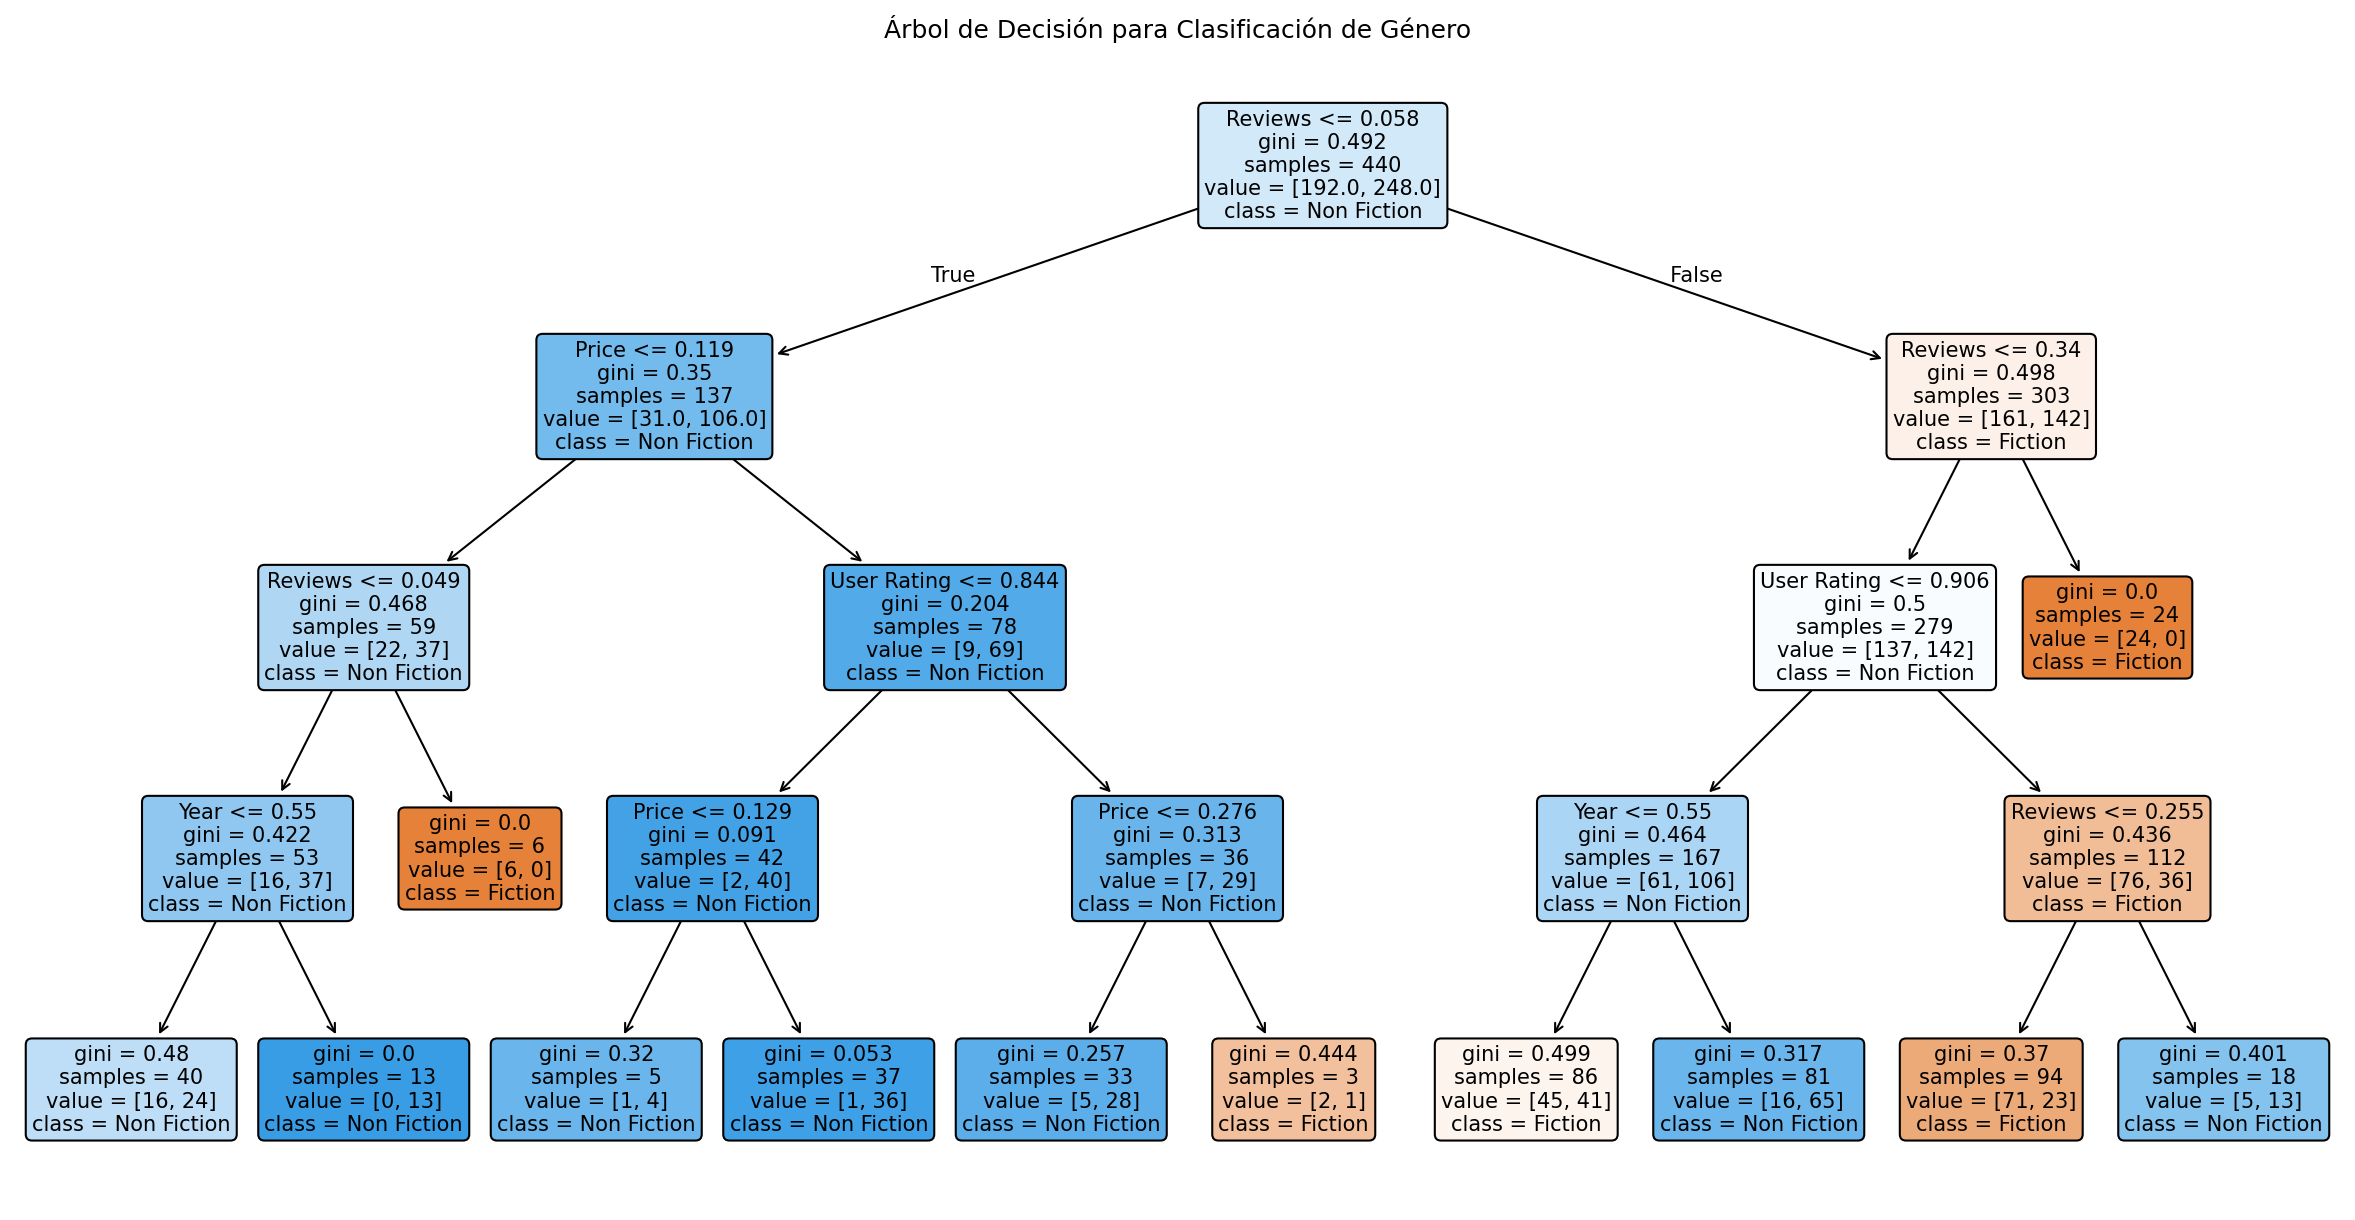

In [ ]:

# obtención del árbol de decisión entrenado
arbol = dt_classifier.named_steps['decisiontreeclassifier']
# nombre de las columnas utilizadas (las numéricas)
columnas_procesadas = list(X_class.columns)

plt.figure(figsize=(20, 10), dpi=150)
plot_tree(
    arbol,
    feature_names=columnas_procesadas,
    class_names=dt_classifier.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión para Clasificación de Género")
plt.show()

### **Importancia de las Variables**

¿Como es que variables como el precio y revie influyen en el genero del libro? algo que ha simple vista no tiene relacion, pero podemos observar que de alguna manera, esto influye en decidir cual es el género del libr

/tmp/ipykernel_2590/724139382.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancias, x='Importancia', y='Característica', palette='viridis')


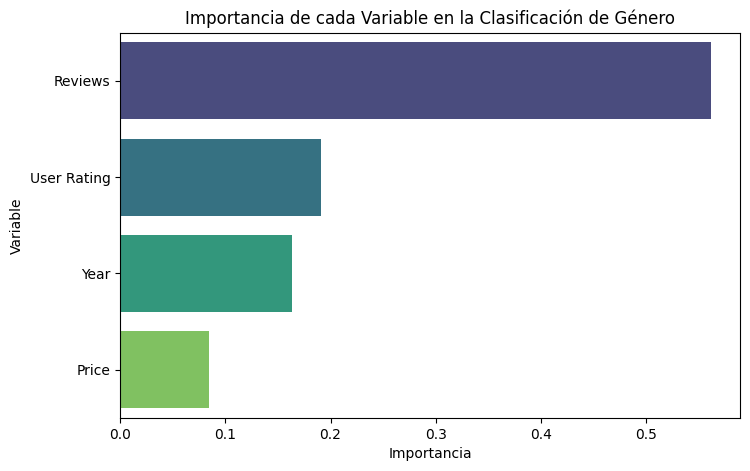

In [ ]:
# extraer cuales son las columnas con mas importancia de las variables del árbol entrenado
importancias = modelo_arbol.feature_importances_

# subdata frame con estos datos
df_importancias = pd.DataFrame({
    'Característica': columnas_procesadas,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

# graficar
plt.figure(figsize=(8, 5))
sns.barplot(data=df_importancias, x='Importancia', y='Característica', palette='viridis')
plt.title('Importancia de cada Variable en la Clasificación de Género')
plt.ylabel('Variable')
plt.show()

# **Interpretación de resultados**

Despues de realizar el modelo de arbol de desición para poder clasificar los libros por su genero, me sorprendio que las variables numericas pudieran ser utilizadas para este objetivo, ya que como se menciono en el código de la grafica anterior, no parece existir una relacion directa.
Sin embargo, podemos observar como la varible que más influye es la de el numero de reviews por libro, no la claificación promedio ni el precio, sino cuanta popularidad tiene cada libro, independientemente de que se clasifique como "bueno" o "malo" por los ususarios.

COn esto podemos concluir que, el aspecto mas importante, si hablamos de variables numericas, es la popularidad, descubriendo que mientras mas popular sea libro, es mas probables que este sea de ficcion, por el otro lado, libros menos populares pertenecen al genero de no ficcion, donde podemos encontrar libros educativos, de autoayuda, etc.

Continuando con la interpretacion, la columna que le sigue a la clasificacion del genero de libros es la clasificación promedio dada por los usuarios. Podemos observar, como la calidad del libro queda como segundo criterio en nuestro arbol, pudiendo notar que se suele clasifcar con mejor calificación libros que no son de ficcion.


Un resumen de como este modelo clasifico el genero de libros puede ser:
a más numero de calificaciones = el genero es ficcion
a mejor calificación = el genero es no ficción